# 09 - Visualization

So far, we have imported raw data and cleaned it into a table that is suitable for analysis. A table of numbers is where the work happens; it is almost never where the work *ends*. This session is about the other half - turning a table into a figure somebody else can read.

This notebook covers the following topics:

- Figures and axes - `fig`, `ax`, and why the one-liner runs out
- Getting the table into shape - long and wide, `pivot` and `melt`
- Four questions, four charts - line, bar, scatter, histogram
- Making a chart readable - labels, limits, scales, ticks, reference lines
- Several panels in one figure - `plt.subplots` with more than one set of axes, and the same charts straight from pandas
- A function that draws a figure - the same plot for any region you hand it
- Saving a figure - `savefig`, and what a figure is for

Two things are worth saying before we start.

**A chart is not a decoration.** Every figure in this notebook is an argument about the data, and the same table supports several different arguments depending on what you draw.

**A chart fails quietly.** A wrong number often looks wrong. A wrong figure looks exactly like a right one - it just draws a line through a gap, or connects the points in the wrong order.

As always, we start by importing what we need and loading our own data.

`matplotlib` is the plotting library. Almost everything we want lives in one of its modules, `matplotlib.pyplot`, and it is always imported under the name `plt` - that abbreviation is as universal as `pd` for pandas.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

And here is last week's work, packed into a function. Last week's `load_emissions` read the emissions file, dropped the rows with no total and added emissions per person. `load_panel` does that and then everything we did with the second file: tidy the lookup file's column name, merge on the key that matches, check the shape of the merge with `validate=`, and drop the aggregates. Nothing in it is new. That was a session; now it is the setup.

The two paths are default arguments, so `load_panel()` with no arguments reads the course files.

In [14]:
def load_panel(emissions_path="../data/co2_emissions.csv", info_path="../data/country_info.csv"):
    """
    Read the emissions and country files and return one clean panel.

    Parameters
    ----------
    emissions_path : str
        Path to the emissions CSV file.
    info_path : str
        Path to the country information CSV file.

    Returns
    -------
    DataFrame
        One row per country per year, with region and income level added,
        rows missing total emissions dropped, the aggregates removed and
        emissions per person added as a column.
    """
    co2 = pd.read_csv(emissions_path)
    co2 = co2.dropna(subset=["co2_total"])
    co2["co2_pc"] = co2["co2_total"] * 1_000_000 / co2["population"]

    info = pd.read_csv(info_path)
    info = info.rename(columns={"incomeLevel": "income_level"})

    panel = co2.merge(
        info[["code", "region", "income_level"]],
        on="code",
        how="left",
        validate="many_to_one",
    )

    return panel[panel["region"] != "Aggregates"]

In [15]:
panel = load_panel()

print("rows:     ", len(panel))
print("countries:", panel["code"].nunique())
print("years:    ", panel["year"].min(), "-", panel["year"].max())

panel.head()

rows:      4872
countries: 203
years:     2000 - 2023


,country,code,year,co2_total,population,urban,gdp_pc,electricity,agriculture,nat_resources,renew_energy,co2_pc,region,income_level
0,Afghanistan,AFG,2000,1.0093,20130327,18.558,174.93,4.4,57.946,NaN,45.0,0.050138,"Middle East, North Africa, Afghanistan & Pakistan",Low income
1,Afghanistan,AFG,2001,0.9402,20284307,18.741,138.71,9.3,57.947,NaN,45.6,0.046351,"Middle East, North Africa, Afghanistan & Pakistan",Low income
2,Afghanistan,AFG,2002,0.9388,21378117,18.941,178.95,14.1,57.940,1.2761,37.8,0.043914,"Middle East, North Africa, Afghanistan & Pakistan",Low income
3,Afghanistan,AFG,2003,1.0172,22733049,19.160,198.87,19.0,58.084,0.7313,36.7,0.044745,"Middle East, North Africa, Afghanistan & Pakistan",Low income
4,Afghanistan,AFG,2004,0.9024,23560654,19.399,221.76,23.8,58.151,0.4589,44.2,0.038301,"Middle East, North Africa, Afghanistan & Pakistan",Low income


203 countries, 24 years each, no aggregates. Everything in this notebook is drawn from that table.

## Figures and axes

Last week ended with a chart, and it took one line:

<Axes: title={'center': 'East Asia & Pacific: total CO₂, Mt'}, xlabel='year'>

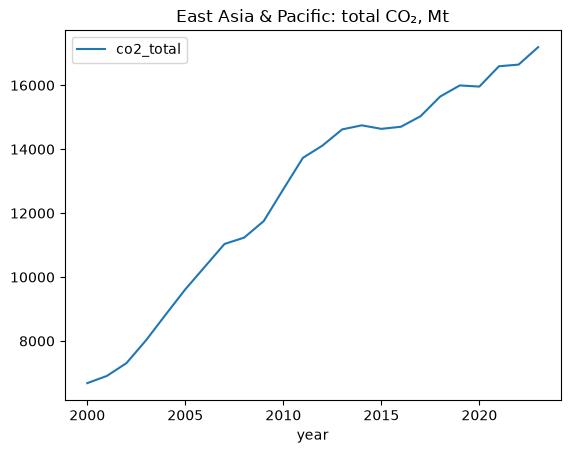

In [16]:
east_asia = panel[panel["region"] == "East Asia & Pacific"]
yearly = east_asia.groupby("year")["co2_total"].sum().reset_index()

yearly.plot(x="year", y="co2_total", title="East Asia & Pacific: total CO₂, Mt")

`.plot()` is a pandas method, and for a quick look at a column it is unbeatable. It also runs out quickly. The y-axis has no label and no units. The legend says `co2_total`, which is a column name rather than English. And the moment you want two of these side by side, or a line drawn across one of them, there is nowhere to say *which* picture you mean.

So we go one level down, to the library pandas is calling.

### The two objects

matplotlib gives you two things, and every plotting instruction is addressed to one of them.

| Object | What it is | What you ask it for |
|---|---|---|
| `fig` | the whole picture - the sheet of paper | how big it is, a title over everything, saving it to disk |
| `ax` | one set of axes drawn on that sheet - the box the data goes in | the data itself, axis labels, limits, ticks, the legend |

Every plotting cell in this notebook ends with `plt.show()`. Almost every matplotlib method hands something back and a notebook prints whatever the last line of a cell evaluates to. `plt.show()` draws the figure and returns nothing, which keeps the cell quiet.

You make both objects at once with `plt.subplots()`, which returns them as a pair:

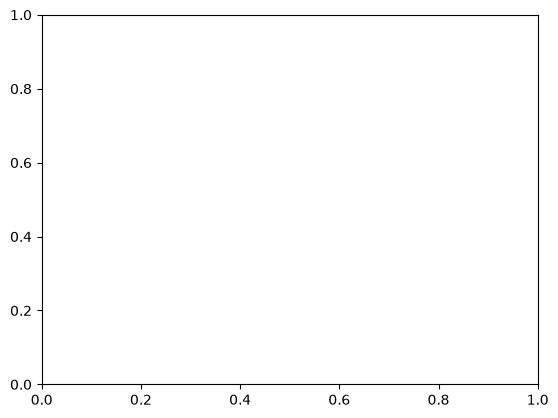

In [17]:
fig, ax = plt.subplots()

plt.show()


An empty figure with one empty set of axes on it.

Now put something in it. The methods are named for what they draw: `ax.plot` draws lines, and the ones that set text on the axes are `ax.set_xlabel`, `ax.set_ylabel` and `ax.set_title`. Each takes the data or the string you want.

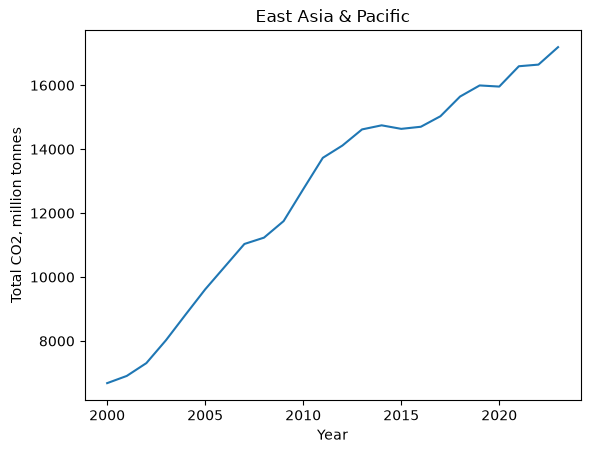

In [18]:
fig, ax = plt.subplots()

ax.plot(yearly["year"], yearly["co2_total"])

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.set_title("East Asia & Pacific")

plt.show()

### Size

`plt.subplots` takes `figsize`, a pair of numbers giving width and height **in inches**. The default is 6.4 by 4.8, which is fine for a quick look and usually too small for anything with a legend. Almost every figure from here on passes one.

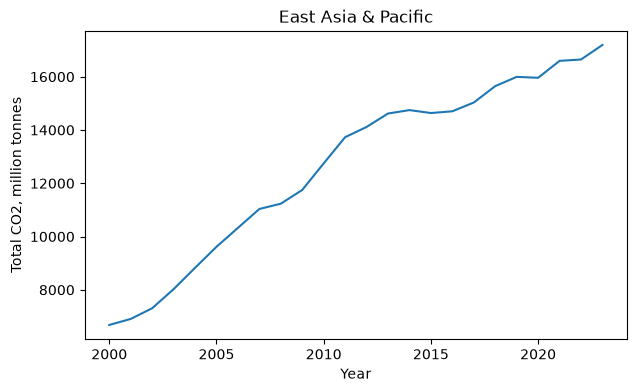

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(yearly["year"], yearly["co2_total"])

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.set_title("East Asia & Pacific")

plt.show()

## Getting the table into shape

Here is the first real decision, and it is not a plotting decision at all - it is about the table.

We want **one line per region**, all seven on one chart. Start from last week's result: group by region and year, and total the emissions.

In [20]:
regional = panel.groupby(["region", "year"])["co2_total"].sum().reset_index()

print(regional.shape)
regional.head().round(1)

(168, 3)


,region,year,co2_total
0,East Asia & Pacific,2000,6681.3
1,East Asia & Pacific,2001,6907.1
2,East Asia & Pacific,2002,7308.2
3,East Asia & Pacific,2003,8024.2
4,East Asia & Pacific,2004,8825.7


168 rows - seven regions times 24 years - and three columns. Every row is one region in one year, and the thing being measured is named by the *value* in the `region` column rather than by which column it sits in.

That shape has a name: **long**. It is what `groupby` gives you, and it is what almost every pandas operation wants.

The other shape is **wide**: one row per year, one *column* per region, and the emissions figures in the body of the table.

| | Long | Wide |
|---|---|---|
| One row is | one region in one year | one year |
| Regions are | values in a column | column names |
| Adding an eighth region | adds 24 rows | adds a column |
| Good for | `groupby`, `merge`, filtering | reading, and plotting one line per column |

Neither is more correct. They hold identical information, and you move between them constantly.

### `pivot` goes long to wide

`pivot` takes three arguments: 
- `index` is the column whose values stays as rows (becomes the new index)
- `columns` is the column whose values become the new column names
- `values` is the column that fills the body

In [21]:
wide = regional.pivot(index="year", columns="region", values="co2_total")

print(wide.shape)
wide.head()

(24, 7)


region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
year,,,,,,,
2000,6681.3359,6906.3139,1351.0142,1516.6216,6472.0194,1039.7875,571.5449
2001,6907.0830,6949.6742,1352.6127,1592.0497,6412.1537,1061.6542,592.2733
2002,7308.1604,6946.8150,1353.8011,1644.8627,6280.9583,1101.4619,596.0773
2003,8024.1583,7189.9360,1385.8478,1704.5605,6366.7770,1136.3235,631.9437
2004,8825.6635,7206.7729,1449.5072,1809.0303,6439.9085,1223.4122,667.4089


24 rows by 7 columns, and the year has become the index. Note that the columns come out in alphabetical order - `pivot` sorts them.

In [22]:
wide = wide.reset_index()

wide.head()

region,year,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
0,2000,6681.3359,6906.3139,1351.0142,1516.6216,6472.0194,1039.7875,571.5449
1,2001,6907.0830,6949.6742,1352.6127,1592.0497,6412.1537,1061.6542,592.2733
2,2002,7308.1604,6946.8150,1353.8011,1644.8627,6280.9583,1101.4619,596.0773
3,2003,8024.1583,7189.9360,1385.8478,1704.5605,6366.7770,1136.3235,631.9437
4,2004,8825.6635,7206.7729,1449.5072,1809.0303,6439.9085,1223.4122,667.4089


### `melt` goes wide to long

`melt` is the inverse, and it also takes three arguments:
- `id_vars` names the columns to keep as they are; everything else is collapsed into two new columns
- `var_name` is the name to use for the "variable" column
- `value_name` is the name to use for the "value" column

In [23]:

back = wide.melt(
    id_vars="year",
    var_name="region",
    value_name="co2_total",
)

print(back.shape)
back.head().round(1)

(168, 3)


,year,region,co2_total
0,2000,East Asia & Pacific,6681.3
1,2001,East Asia & Pacific,6907.1
2,2002,East Asia & Pacific,7308.2
3,2003,East Asia & Pacific,8024.2
4,2004,East Asia & Pacific,8825.7


168 rows again. 

### Aggregate before you pivot

`pivot` cannot invent an answer. If more than one row would land in the same cell, it stops:

In [24]:
# ValueError
# panel.pivot(index="year", columns="region", values="co2_total")

`Index contains duplicate entries, cannot reshape`. Of course: `panel` has 37 East Asian countries in 2023, so the cell at row 2023, column "East Asia & Pacific" has 37 candidates and `pivot` will not choose between them.

This is a **good** error. It is refusing to guess. The fix is to say what you meant - group and aggregate first, which is exactly what `regional` is - and only then reshape.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Reshape a table. In a single cell, start from the long table below - total emissions by income level and year - and use <code>pivot</code> to turn it into a wide table with one row per year and one column per income level. Print the shape of the long table and of the wide one.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>df = load_panel()

by_income = df.groupby(["income_level", "year"])["co2_total"].sum().reset_index()</code></pre>

</div>

In [25]:
df = load_panel()
by_income = df.groupby(["income_level", "year"])["co2_total"].sum().reset_index()


by_income # this is a long table, and we want to make it a wide table using pivot.

wide_by_income = by_income.pivot(index="year", columns="income_level", values="co2_total")
print("wide:",wide_by_income.shape)
print("long:",by_income.shape)
wide_by_income

wide: (24, 4)
long: (96, 3)


income_level,High income,Low income,Lower middle income,Upper middle income
year,,,,
2000,15214.8280,162.4278,1831.7221,7329.6595
2001,15260.2640,168.6942,1888.1525,7550.3901
2002,15178.8329,167.0995,1932.6087,7953.5956
2003,15503.4858,173.8845,1974.8684,8787.3081
2004,15649.6813,180.1427,2105.1955,9686.6840
2005,15715.1271,198.6710,2182.9340,10565.6075
2006,15701.9907,207.9513,2298.8648,11412.7585
2007,15877.6313,204.2982,2440.6864,12213.7567
2008,15576.8088,217.2972,2575.7517,12577.2868


### So which shape do you want?

For a chart with one line per group, either works. We start from a fresh copy of the data, and this time the year stays in the index of the wide table, where it will be the x-axis of every line.

In [26]:
panel = load_panel()

regional = panel.groupby(["region", "year"])["co2_total"].sum().reset_index()

print(regional.shape)
regional.head()

(168, 3)


,region,year,co2_total
0,East Asia & Pacific,2000,6681.3359
1,East Asia & Pacific,2001,6907.0830
2,East Asia & Pacific,2002,7308.1604
3,East Asia & Pacific,2003,8024.1583
4,East Asia & Pacific,2004,8825.6635


From the long table, the most direct way is the one you already know: loop over the region names, keep the rows for each one with a filter, and draw them. `label=` gives each line a name, and `ax.legend()` collects the names into a legend.

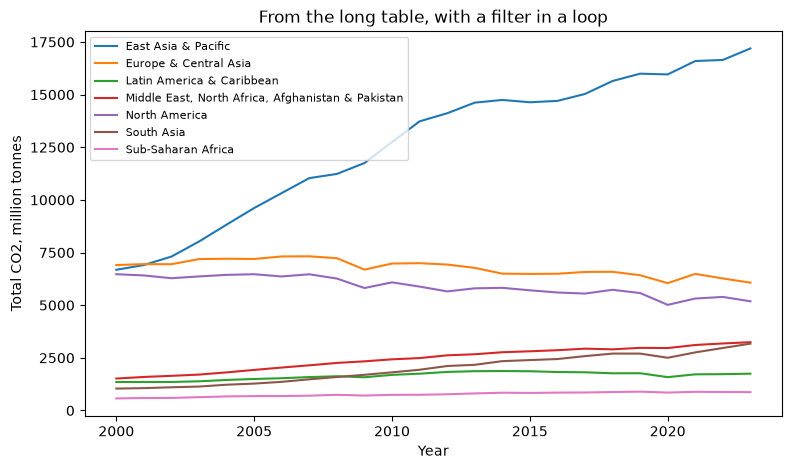

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))

for region in regional["region"].unique():
    rows = regional[regional["region"] == region]
    ax.plot(rows["year"], rows["co2_total"], label=region)

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.legend(fontsize=8)
ax.set_title("From the long table, with a filter in a loop")

plt.show()

Notice that `groupby` can do the filtering for you. A grouped object with no aggregation attached can be looped over directly: each turn of the loop gives you the group's name and the rows belonging to it - exactly the `region` and `rows` we built by hand above.

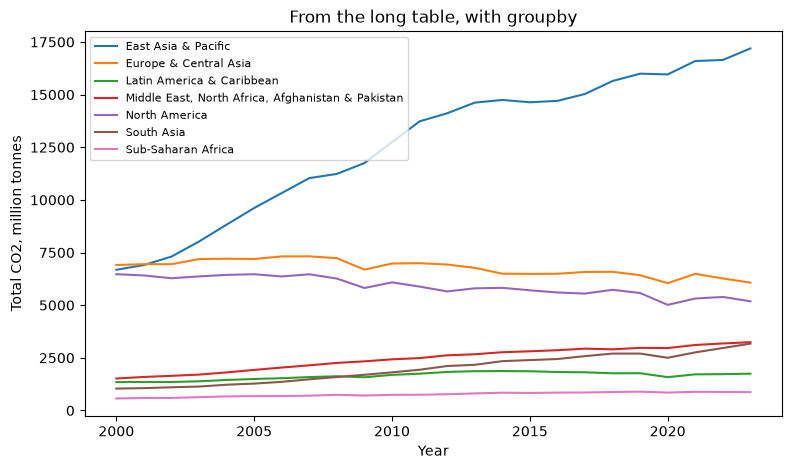

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))

for name, group in regional.groupby("region"):
    ax.plot(group["year"], group["co2_total"], label=name)

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.legend(fontsize=8)
ax.set_title("From the long table, with groupby")

plt.show()

The same figure, with no `.unique()` and no filter. That is the *split* of split-apply-combine, with the apply - here, drawing - left to you.

Now the same figure from the wide table. Each region is already a column, so the loop runs over the columns, and the year comes from the index:

In [29]:
wide = regional.pivot(index="year", columns="region", values="co2_total")

print(wide.shape)
wide.head()

(24, 7)


region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
year,,,,,,,
2000,6681.3359,6906.3139,1351.0142,1516.6216,6472.0194,1039.7875,571.5449
2001,6907.0830,6949.6742,1352.6127,1592.0497,6412.1537,1061.6542,592.2733
2002,7308.1604,6946.8150,1353.8011,1644.8627,6280.9583,1101.4619,596.0773
2003,8024.1583,7189.9360,1385.8478,1704.5605,6366.7770,1136.3235,631.9437
2004,8825.6635,7206.7729,1449.5072,1809.0303,6439.9085,1223.4122,667.4089


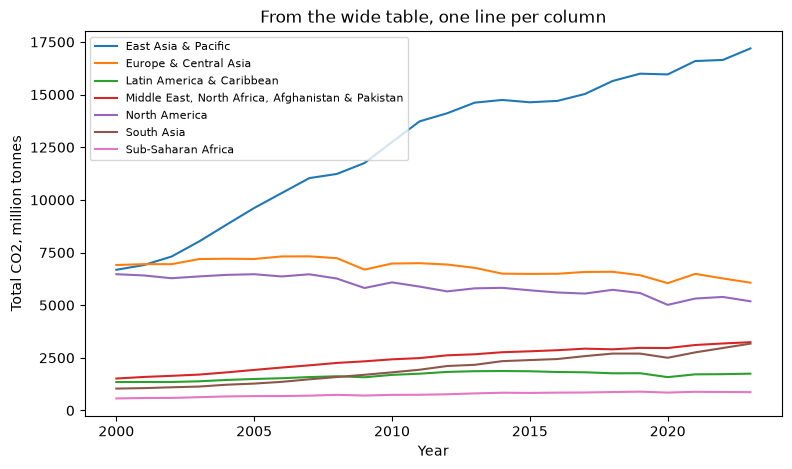

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))

for region in wide.columns:
    ax.plot(wide.index, wide[region], label=region)

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.legend(fontsize=8)
ax.set_title("From the wide table, one line per column")

plt.show()

No filtering at all. In the wide table the data for each line is already sitting in a column, ready to draw - in that sense the wide table has **the shape of the chart: one column, one line, and the column name is the label.**

The rule that follows:
- **Long for computing.** `groupby`, `merge`, filtering and every check from last week are easier, and sometimes only possible, on a long table.
- **Wide for reading, and for drawing one line per column.** A human comparing four regions in 2010 reads the wide table far faster.

Keep the long version, and reshape at the last minute, for the chart.

## Four questions, four charts

There are hundreds of chart types and you will use four of them. What separates them is not what they look like but **what question they answer**, so that is how they are worth learning.

| The question you are asking | The chart | The method |
|---|---|---|
| How did something change over time? | line | `ax.plot` |
| How do a handful of categories compare? | bar | `ax.bar`, `ax.barh` |
| Are these two variables related? | scatter | `ax.scatter` |
| How is one variable spread out? | histogram | `ax.hist` |

Pick the chart from the question, not from the table. A table of seven regions in 2023 will happily produce all four, but only one of them will answer the question that you have in mind.

### Change over time: `ax.plot`

A line chart draws a straight segment between each pair of points you give it, **and says nothing at all about what happened in between.** That is fine when the points are a year apart and the world is smooth. It is an issue when some of the points are missing and you removed them before plotting.

Here is a real case from the file we have been using all along. `nat_resources` is the value of a country's natural resources - oil, gas, minerals - as a percentage of its GDP, and Timor-Leste's oil revenues arrived partway through the period.

In [31]:
timor = panel[panel["country"] == "Timor-Leste"].sort_values("year")
rents = timor.set_index("year")["nat_resources"]

print("years with no figure:", list(rents[rents.isna()].index))
rents.round(2)

years with no figure: [2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2022, 2023]


year
2000     0.40
2001     0.35
2002     0.39
2003     0.52
2004      NaN
2005      NaN
2006      NaN
2007      NaN
2008      NaN
2009      NaN
2010      NaN
2011      NaN
2012      NaN
2013      NaN
2014      NaN
2015    79.43
2016    44.56
2017    44.87
2018    62.77
2019    44.90
2020    34.39
2021    34.73
2022      NaN
2023      NaN
Name: nat_resources, dtype: float64

Thirteen of the 24 years have no figure at all, and eleven of those are one unbroken run in the middle. Now the thing people often do: drop the missing rows and plot what is left.

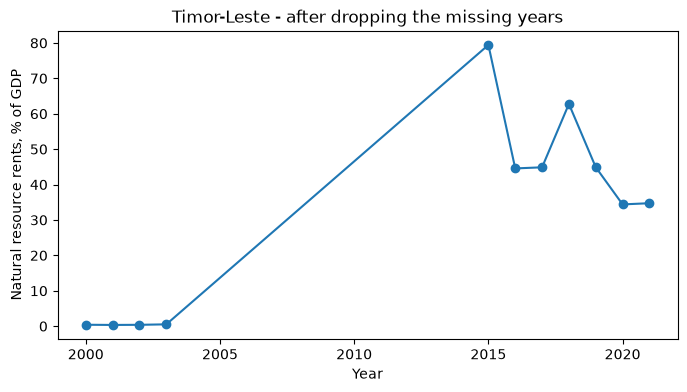

In [32]:
dropped = timor.dropna(subset=["nat_resources"])

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(dropped["year"], dropped["nat_resources"], marker="o")

ax.set_xlabel("Year")
ax.set_ylabel("Natural resource rents, % of GDP")
ax.set_title("Timor-Leste - after dropping the missing years")

plt.show()

That figure says Timor-Leste's resource rents climbed steadily from under 1% of GDP in 2003 to nearly 80% in 2015. A twelve-year ramp, smooth and convincing.

**No such climb was observed.** There is no figure for any year between 2004 and 2014. Everything between those two points is a straight line matplotlib drew because we handed it two points and asked for a line. Read the chart at 2009 and it tells you about 40% - a number that appears in no file anywhere.

Do it without dropping anything and the line breaks. `ax.plot` will not draw through a `NaN`, so the gap in the data becomes a gap in the figure, and a reader can see there is something they do not know.

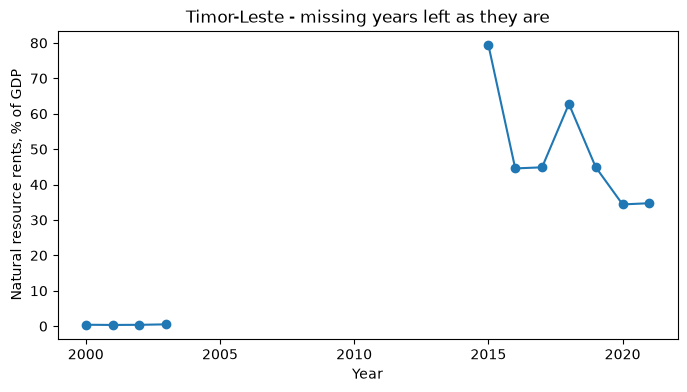

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(timor["year"], timor["nat_resources"], marker="o")

ax.set_xlabel("Year")
ax.set_ylabel("Natural resource rents, % of GDP")
ax.set_title("Timor-Leste - missing years left as they are")

plt.show()

> ⚠️ **Warning:** `dropna()` before a line chart turns *"we have no measurement"* into *"we measured a straight line"*. Drop rows only when you mean **these observations do not exist**. When you mean **these are missing**, leave them as `NaN` and let the gap show.

There is a second version of the same trap, and it is worse because there is nothing to see even in the data: rows that were **never in the file**. If a country simply has no 2008 row, the table looks complete and the line still bridges the gap. That is what `resample` was for last week - it builds a row for every period from the calendar, so a period with no observation arrives as `NaN` instead of quietly not being there.

> ⚠️ **Warning:** `ax.plot` connects points in the order you give them, not in order of x. 

#### Shading under the line

`ax.fill_between` fills the space between a line and something else - by default the x-axis, which turns a line chart into an **area chart**. It takes the same x and y you gave `ax.plot`, and `alpha` again so the fill sits behind the line rather than on top of it.

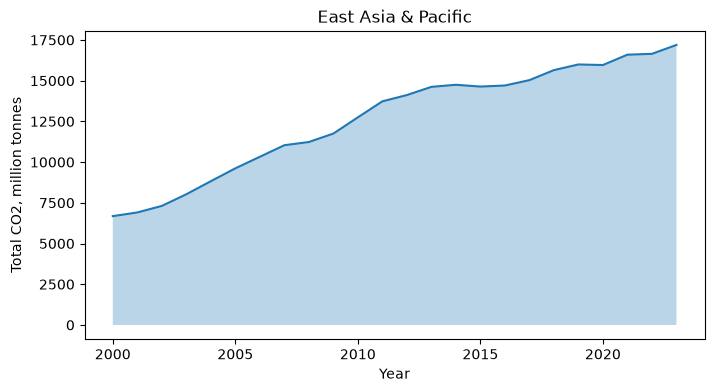

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(yearly["year"], yearly["co2_total"])
ax.fill_between(yearly["year"], yearly["co2_total"], alpha=0.3)

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.set_title("East Asia & Pacific")

plt.show()

Filling under a line only makes sense when the quantity really does start at zero: a reader takes the shaded area as an amount, so it has to be measured from nothing.

Given a second series instead, `ax.fill_between(x, low, high)` shades the band between two lines - the usual way to draw a range, a forecast interval or a min-to-max spread.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Spot the mistake. The code below draws Norway's total emissions over time, and the figure it draws is wrong. Run it in the cell underneath, find out what is wrong, and fix it.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>df = load_panel()

norway = df[df["country"] == "Norway"].sort_values("co2_total", ascending=False)
print(norway[["year", "co2_total"]].head(3))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(norway["year"], norway["co2_total"])

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.set_title("Norway")

plt.show()</code></pre>

</div>

      year  co2_total
4103  2023    41.6042
4102  2022    43.5471
4101  2021    44.4278


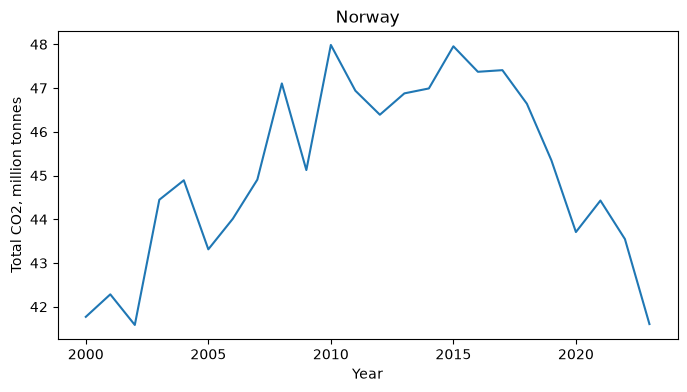

In [35]:
df = load_panel()

norway = df[df["country"] == "Norway"].sort_values("year", ascending=False)
print(norway[["year", "co2_total"]].head(3))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(norway["year"], norway["co2_total"])

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.set_title("Norway")

plt.show()

# EZ: It sorted by co2_total, when it should have been sorted by year!. Or not sorted at all would also have worked

### Comparing categories: `ax.bar`

`ax.bar` takes the category names and the heights.

In [36]:
panel = load_panel()

year_2023 = panel[panel["year"] == 2023]
totals = year_2023.groupby("region")["co2_total"].sum().sort_values(ascending=False)

totals.head()

region
East Asia & Pacific                                  17192.7211
Europe & Central Asia                                 6069.0815
North America                                         5185.6227
Middle East, North Africa, Afghanistan & Pakistan     3242.4211
South Asia                                            3173.8789
Name: co2_total, dtype: float64

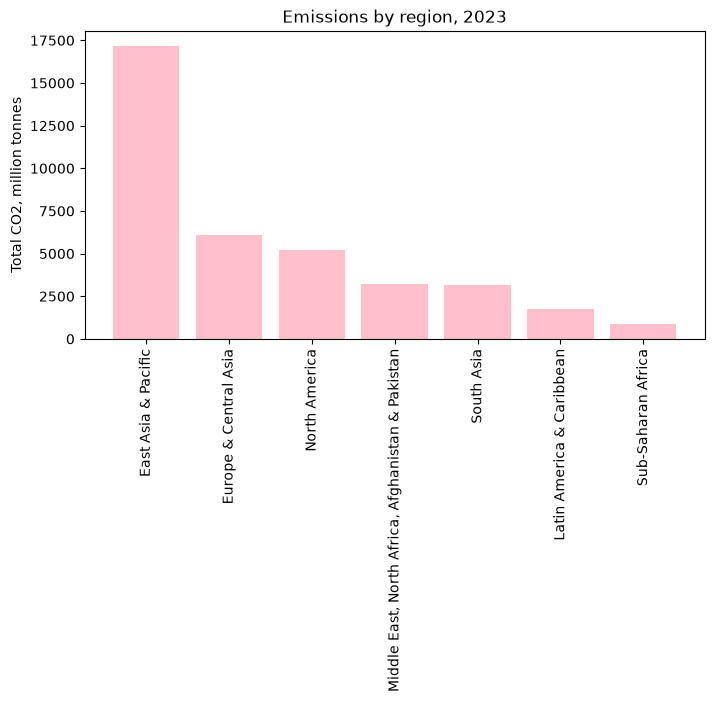

In [37]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(totals.index, totals.values, color="pink")

ax.set_ylabel("Total CO2, million tonnes")
ax.set_title("Emissions by region, 2023")
ax.tick_params(axis="x", rotation=90)

plt.show()

`ax.tick_params` controls how the tick marks and their labels are drawn - here `axis` says which axis and `rotation` says by how many degrees. This properly displays the labels without overlap.

An alternative is to turn the *chart*. `ax.barh` draws horizontal bars, so the category labels run along the y-axis where there is as much room as you want. Note that a horizontal bar chart is read from the bottom up, so sorting **ascending** puts the biggest bar at the top.

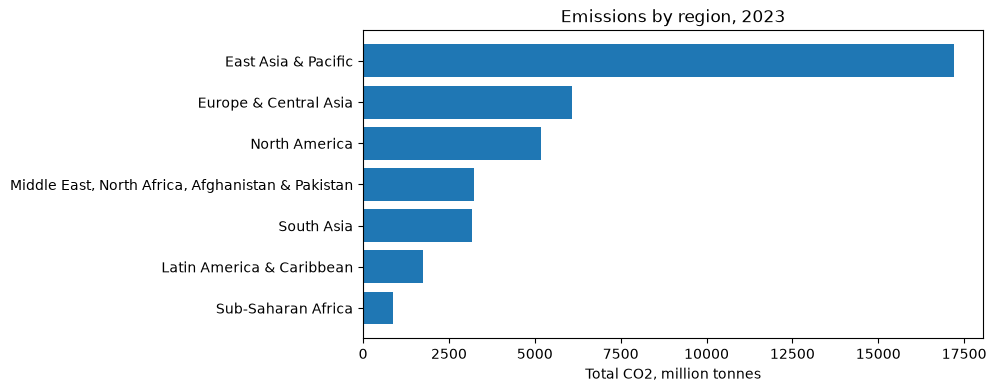

In [38]:
totals_up = year_2023.groupby("region")["co2_total"].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(totals_up.index, totals_up.values)

ax.set_xlabel("Total CO2, million tonnes")
ax.set_title("Emissions by region, 2023")

plt.show()

> 💡 **Tip:** Sort before you draw a bar chart. Categories have no natural order, so unless there is a real one - months, income bands, years - the useful order is by size, and it costs one call to `sort_values`.

#### An average instead of a total

The bar chart above displays total emissions. Here is the same chart of an **average** instead - emissions per person, averaged across the countries of each region.

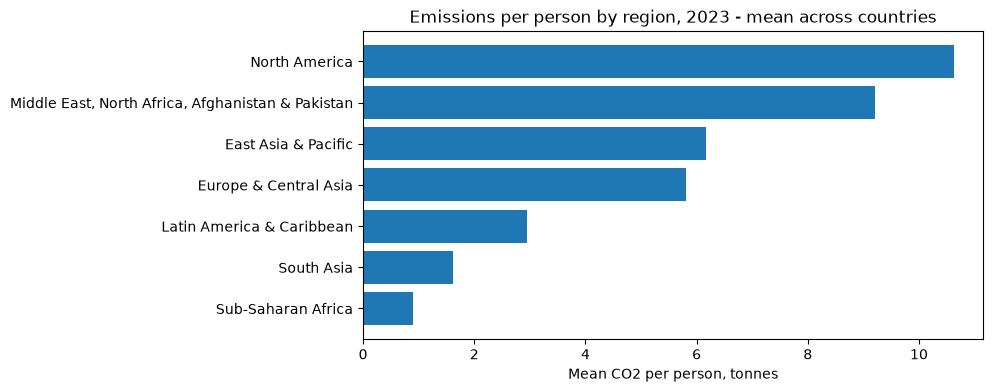

In [39]:
mean_pc = year_2023.groupby("region")["co2_pc"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(mean_pc.index, mean_pc.values)

ax.set_xlabel("Mean CO2 per person, tonnes")
ax.set_title("Emissions per person by region, 2023 - mean across countries")

plt.show()

North America at the top, Sub-Saharan Africa at the bottom.

The title says *mean across countries*, and that is not a detail. Last week showed that a mean across a region's countries and the emissions of an average person in the region are different numbers - for the Middle East and North Africa, more than twice as large. A chart of a summary statistic should say which statistic it is.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Draw a sorted bar chart. In a single cell, take the ten countries with the highest emissions per person (<code>co2_pc</code>) in 2023 and draw them as a horizontal bar chart with the largest bar at the top, an axis label giving the units, and a title.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>df = load_panel()</code></pre>

</div>

Text(0, 0.5, 'Country')

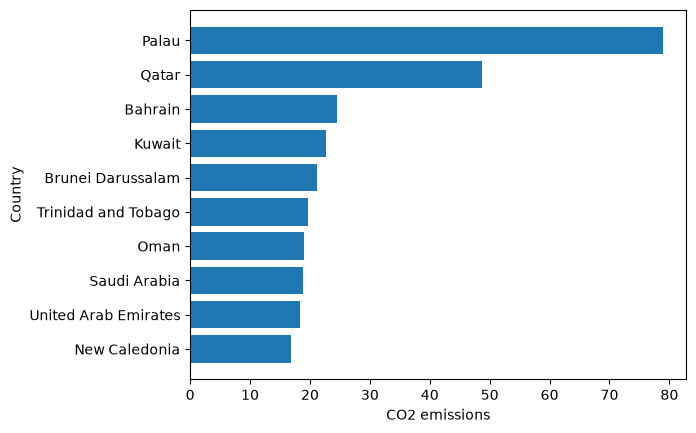

In [40]:
df = load_panel()

df_2023 = df[df["year"] == 2023]
top_ten = df_2023.groupby("country")["co2_pc"].sum().sort_values(ascending=True).tail(10)

fig, ax = plt.subplots()

ax.barh(top_ten.index, top_ten.values)
ax.set_xlabel("CO2 emissions")
ax.set_ylabel("Country")

### Two variables together: `ax.scatter`

A scatter plot asks whether two measurements move together. It takes an x and a y and draws one point per row - so unlike everything above, it does **not** want a summary. It wants the rows.

Richer countries emit more. Do they?

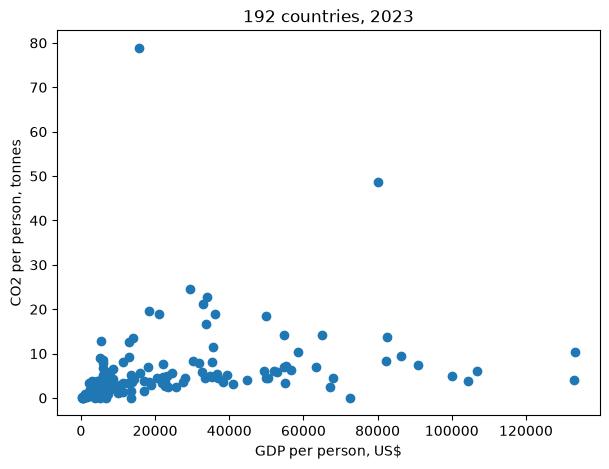

In [41]:
panel = load_panel()

year_2023 = panel[panel["year"] == 2023]
points = year_2023.dropna(subset=["gdp_pc", "co2_pc"])

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(points["gdp_pc"], points["co2_pc"])

ax.set_xlabel("GDP per person, US$")
ax.set_ylabel("CO2 per person, tonnes")
ax.set_title(f"{len(points)} countries, 2023")

plt.show()

Most of the data is jammed into the left-hand bottom of the figure. That is because GDP per person runs from about 250 dollars to about 133 000 - a factor of over 500 - and a linear axis gives the poorest hundred countries almost no room.

`ax.set_xscale("log")` puts the x-axis on a **logarithmic** scale, where equal distances are equal *ratios* rather than equal differences: the gap from 1 000 to 10 000 is the same width as the gap from 10 000 to 100 000.

`alpha=0.6` makes each point slightly transparent, so that a place where several points overlap comes out darker instead of looking like one point.

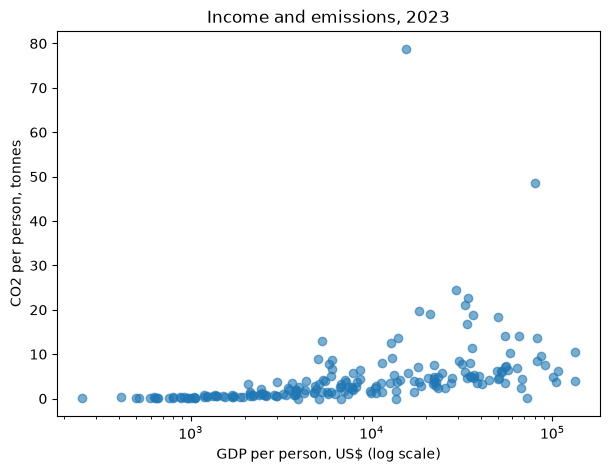

In [42]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(points["gdp_pc"], points["co2_pc"], alpha=0.6)

ax.set_xscale("log")

ax.set_xlabel("GDP per person, US$ (log scale)")
ax.set_ylabel("CO2 per person, tonnes")
ax.set_title("Income and emissions, 2023")

plt.show()

Now the countries are spread across the figure and the relationship is visible. 

> ⚠️ **Warning:** A log scale cannot show zero or a negative number, and it does not tell you when it drops one. Two countries in this table have emissions per person of exactly 0.0 - had we put the *y*-axis on a log scale as well, both would have vanished from the figure with no error and no warning.

#### Color by group

Often we want to assign a different color to the points in a scatter plot based on some characteristic such as region. 

The same loop-over-groups from earlier works here, one `ax.scatter` per region:

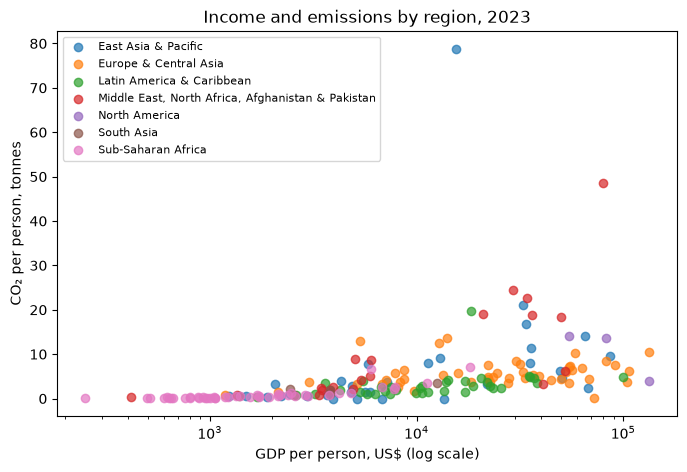

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))

for name, group in points.groupby("region"):
    ax.scatter(group["gdp_pc"], group["co2_pc"], label=name, alpha=0.7)

ax.set_xscale("log")
ax.set_xlabel("GDP per person, US$ (log scale)")
ax.set_ylabel("CO₂ per person, tonnes")
ax.legend(fontsize=8)
ax.set_title("Income and emissions by region, 2023")

plt.show()

matplotlib gives each call the next color in its default cycle, so you get seven colors without asking for any. The cycle has ten entries and then repeats - if you ever loop over more than ten groups, two of them will be drawn identically and the legend will not save you.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Choose the scale. In a single cell, draw a scatter plot of <code>gdp_pc</code> against <code>electricity</code> - the share of the population with access to electricity, in percent - for 2023, with axis labels and a title. Decide whether the x-axis should be on a log scale, and say why in a comment.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>df = load_panel()</code></pre>

</div>

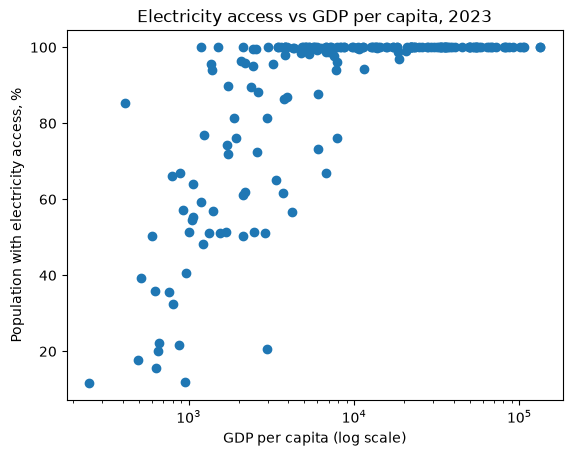

In [44]:
df = load_panel()
df_2023 = df[df["year"] == 2023]

fig, ax = plt.subplots()
ax.scatter(df_2023["gdp_pc"], df_2023["electricity"])
# gdp_pc spans several orders of magnitude, so on a linear axis most countries
# would sit squeezed against the left edge; on a log axis equal distances mean
# equal percentage differences.
ax.set_xscale("log")
ax.set_xlabel("GDP per capita (log scale)")
ax.set_ylabel("Population with electricity access, %")
ax.set_title("Electricity access vs GDP per capita, 2023")
plt.show()


### One variable, spread out: `ax.hist`

The bar chart of regional means replaced 203 countries with seven averages. A histogram does the opposite: it keeps every observation, cuts the range into intervals, and counts how many fall in each.

`edgecolor` draws a line around each bar, which is worth doing always - without it, neighboring bars of similar height merge into one block.

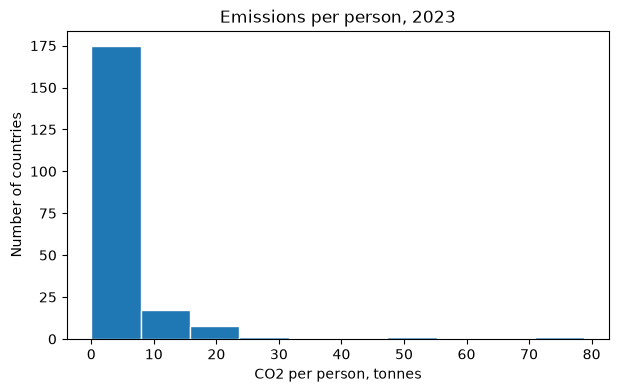

In [45]:
panel = load_panel()

year_2023 = panel[panel["year"] == 2023]

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(year_2023["co2_pc"], edgecolor="white")

ax.set_xlabel("CO2 per person, tonnes")
ax.set_ylabel("Number of countries")
ax.set_title("Emissions per person, 2023")

plt.show()

Almost everything is in the first bar and there is a long thin tail to the right.

Two arguments fix the rest. `bins=` controls how many intervals the range is cut into, and it is the one argument that changes what the chart *says*, so it is worth trying more than one value. And `ax.axvline` draws a vertical line right across the axes at an x value you give it - useful for marking a reference point such as an average.

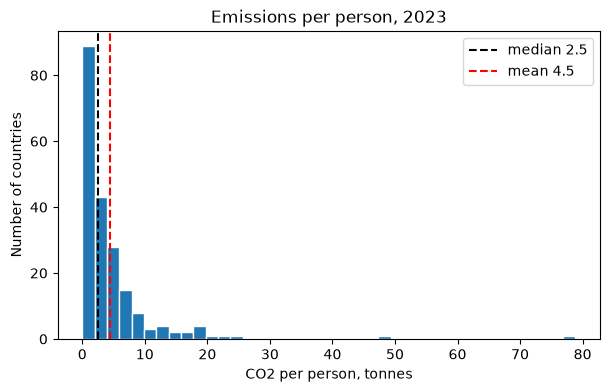

In [46]:
values = year_2023["co2_pc"]

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(values, bins=40, edgecolor="white")

ax.axvline(values.median(), color="black", linestyle="--", label=f"median {values.median():.1f}")
ax.axvline(values.mean(), color="red", linestyle="--", label=f"mean {values.mean():.1f}")

ax.set_xlabel("CO2 per person, tonnes")
ax.set_ylabel("Number of countries")
ax.legend()
ax.set_title("Emissions per person, 2023")

plt.show()

The median is 2.5 tonnes and the mean is 4.5 - the mean is nearly **eighty percent higher**, because a few countries at the far right pull it up while three quarters of the world sits below 5.

That is the argument for this chart type. The bar chart of regional means is built out of exactly these numbers, and could not have told you that the distribution behind them looks like this. 

#### Several distributions at once: `ax.boxplot`

A histogram shows **one** distribution. Comparing seven of them would mean seven histograms, and nobody reads seven histograms.

A **box plot** compresses each distribution into one summary and lines them up. The box covers the middle half of the observations, from the 25th to the 75th percentile; the line inside it is the median; the whiskers reach out to the rest, and anything drawn beyond them is far enough from the middle to be worth looking at individually.

`ax.boxplot` takes a **list** of value sets, one per box, and `tick_labels` names them. `orientation="horizontal"` for the same reason as `ax.barh`: the region names do not fit along the bottom.

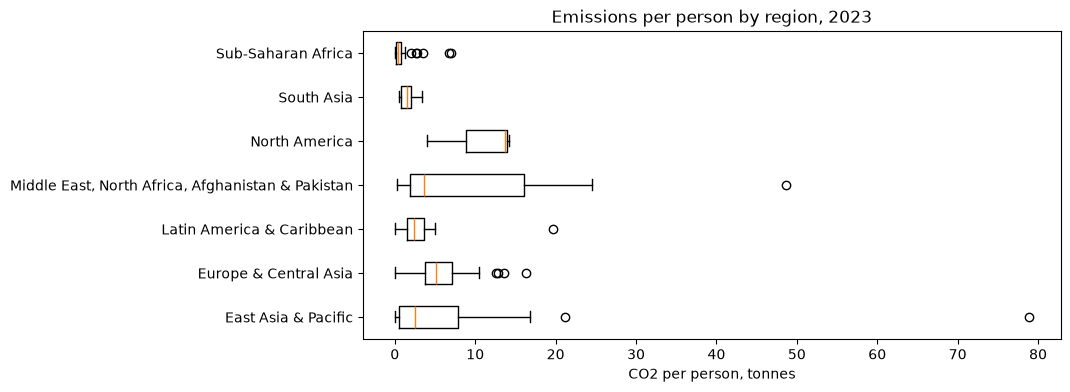

In [47]:
regions = sorted(year_2023["region"].unique())
groups = [year_2023.loc[year_2023["region"] == region, "co2_pc"] for region in regions]

fig, ax = plt.subplots(figsize=(9, 4))

ax.boxplot(groups, tick_labels=regions, orientation="horizontal")

ax.set_xlabel("CO2 per person, tonnes")
ax.set_title("Emissions per person by region, 2023")

plt.show()

Compare that against the bar chart of regional means above. The bars said North America was the worst region; the box plot shows that North American countries are close together, while Europe and Central Asia is spread from under 2 to almost 20 and the Middle East group has a longer tail than either. None of that was visible before.

> 📝 **Note:** `ax.hist` skips missing values without a word, and `ax.boxplot` does not: a group containing a single `NaN` gets no median and no box. Our `co2_pc` has no missing values, because `load_panel` dropped the rows with no total. On other data, `.dropna()` each group before you hand it to `ax.boxplot`.

## Making a chart readable

The four chart types above were about choosing the chart. This one is about finishing it.

A figure that leaves your screen has to survive without you standing next to it. The checklist is short, and none of it is optional:

| Every figure needs | How |
|---|---|
| an x-axis label, **with units** | `ax.set_xlabel` |
| a y-axis label, **with units** | `ax.set_ylabel` |
| a title saying what you are looking at | `ax.set_title` |
| a legend, if there is more than one series | `label=` on each, then `ax.legend()` |
| limits that do not mislead | `ax.set_xlim`, `ax.set_ylim` |
| ticks a human can read | `ax.tick_params`, `ax.grid`, `set_major_formatter` |

We will take one chart and finish it properly. Last week's NASDAQ file: the daily closing level of a US stock index, from February 1971 to December 2025.

In [48]:
nasdaq = pd.read_csv("../data/NASDAQ.csv")
nasdaq["Date"] = pd.to_datetime(nasdaq["Date"], format="%Y-%m-%d")

prices = nasdaq.set_index("Date").sort_index()["NASDAQ"]
monthly = prices.resample("ME").last()

print(len(prices), "trading days ->", len(monthly), "months")
monthly.head()

13842 trading days -> 659 months


Date
1971-02-28    101.3
1971-03-31    106.0
1971-04-30    112.3
1971-05-31    108.2
1971-06-30    107.8
Freq: ME, Name: NASDAQ, dtype: float64

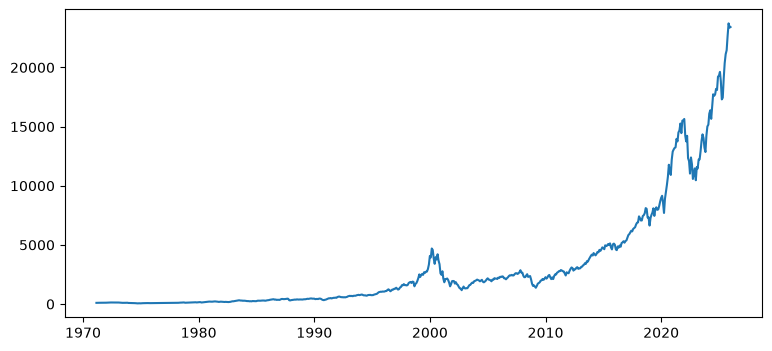

In [49]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(monthly.index, monthly.values)

plt.show()

Two things already work without being asked. The x-axis shows years rather than numbers, because the index is a real datetime after last week's `to_datetime` - that is the whole payoff of converting it. And the line is in date order because we sorted it.

Everything else is wrong.

### Scale

The index started at 100 and ended above 23 000. On a linear axis the first thirty years of the series are a flat line along the bottom, and the crash of 2000 - which took the index down by 78% and was the defining market event of a generation - is a small wiggle.

`ax.set_yscale("log")` is the fix, for the same reason as in the scatter plot: on a log axis a fall of half is the same distance wherever it happens, so a percentage change looks the same size in 1975 as in 2020.

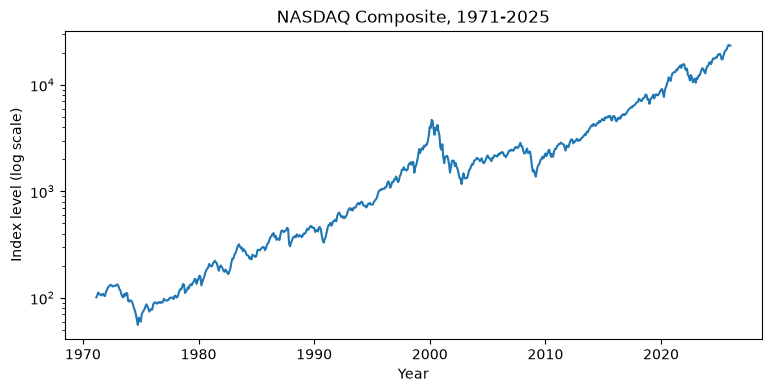

In [50]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(monthly.index, monthly.values)

ax.set_yscale("log")
ax.set_xlabel("Year")
ax.set_ylabel("Index level (log scale)")
ax.set_title("NASDAQ Composite, 1971-2025")

plt.show()

The 1970s are now visible, and so is the fact that the fall after 2000 was far larger than anything before it.

### Grid, limits, and a shaded period

The 2000 Dot-Com Crash started in March that year and it took several years for the market to recover.

We can use `.idxmax()` and `.idxmin()` to get the dates (i.e., the timestamps) of the maximum and minimum prices between 2000 and 2002.

In [51]:
peak_date = prices.loc["2000"].idxmax()
low_date = prices.loc["2002"].idxmin()

print("peak:", peak_date.date(), round(prices.loc[peak_date], 1))
print("low: ", low_date.date(), round(prices.loc[low_date], 1))
print("fall:", round((prices.loc[low_date] / prices.loc[peak_date] - 1) * 100, 1), "%")

peak: 2000-03-10 5048.6
low:  2002-10-09 1114.1
fall: -77.9 %


`ax.grid` draws grid lines. And `ax.axvspan` shades a vertical band between two x values, which is how you mark a period on a time series - `alpha` again to keep it behind the data rather than on top of it.

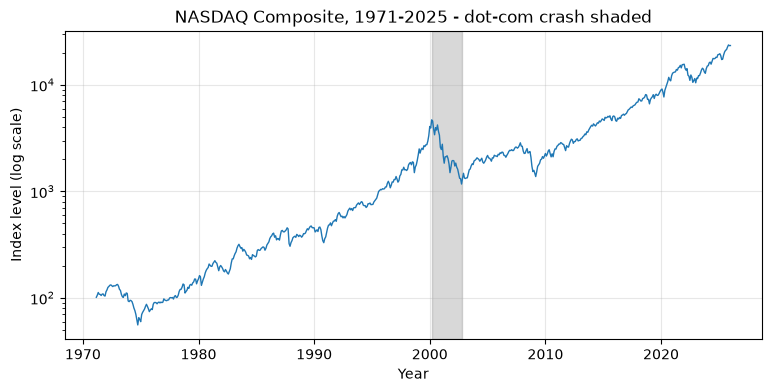

In [52]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(monthly.index, monthly.values, linewidth=1)

ax.axvspan(peak_date, low_date, color="gray", alpha=0.3)

ax.set_yscale("log")
ax.grid(True, alpha=0.3)
ax.set_xlabel("Year")
ax.set_ylabel("Index level (log scale)")
ax.set_title("NASDAQ Composite, 1971-2025 - dot-com crash shaded")

plt.show()

### Limits

`ax.set_xlim` and `ax.set_ylim` set the range of an axis, as a lower and an upper bound. On this figure the x-axis is made of dates, so the x bounds have to be dates too, and `pd.Timestamp` is how you write a single date.

Here we zoom in on the decade around the crash. matplotlib does not rescale the y-axis to the part you zoomed into, so we set that range too.

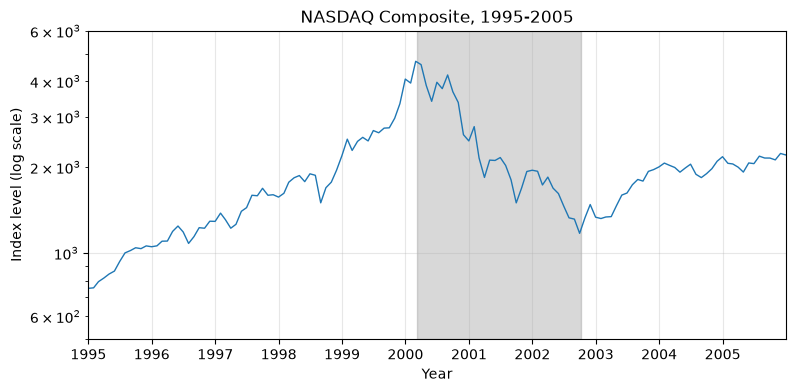

In [53]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(monthly.index, monthly.values, linewidth=1)

ax.axvspan(peak_date, low_date, color="gray", alpha=0.3)

ax.set_yscale("log")
ax.set_xlim(pd.Timestamp("1995-01-01"), pd.Timestamp("2005-12-31"))
ax.set_ylim(500, 6000)

ax.grid(True, alpha=0.3)
ax.set_xlabel("Year")
ax.set_ylabel("Index level (log scale)")
ax.set_title("NASDAQ Composite, 1995-2005")

plt.show()

Limits are where a chart most easily misleads. A y-axis that starts just below the lowest value makes a small change look like a collapse, and a time axis that starts at a convenient low makes almost any series look like a success. Zoom in when the reader needs the detail, and say in the title what range they are looking at.

> 💡 **Tip:** pandas reads date strings almost anywhere - `prices.loc["2019"]` and `df[df["Date"] >= "2020-01-01"]` both work. matplotlib does not. A position on a date axis - in `set_xlim`, `axvline`, `axvspan` or `text` - should always be a real date: a `pd.Timestamp`, or a date you took from the data, like `peak_date`. A plain string fails in some of these methods and happens to work in others, so do not rely on it even when it seems to work.

### Numbers on the axis that a human can read

Look at the y-axis of the full-length figures above. On a log scale matplotlib labels the ticks `10⁰`, `10¹`, `10²` and so on, which is correct and is not how anybody talks about a stock index.

A **formatter** decides how each tick value is turned into text. The ready-made ones live in a module of their own, `matplotlib.ticker`, so it needs its own import - and then you hand one to the axis you want to change. 

In [54]:
import matplotlib.ticker as mtick

Note that we apply the formatter on `ax.yaxis`, the axis object itself, rather than `ax`.

`StrMethodFormatter` takes exactly the format string you already know from f-strings, with `x` standing for the tick value: `"{x:,.0f}"` means *no decimals, comma as a thousands separator*.

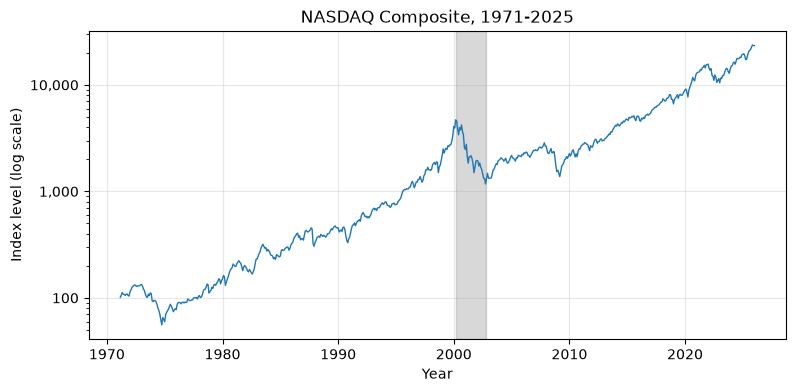

In [55]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(monthly.index, monthly.values, linewidth=1)
ax.axvspan(peak_date, low_date, color="gray", alpha=0.3)

ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

ax.grid(True, alpha=0.3)
ax.set_xlabel("Year")
ax.set_ylabel("Index level (log scale)")
ax.set_title("NASDAQ Composite, 1971-2025")

plt.show()

`1`, `10`, `100`, `1,000`, `10,000` - the same axis, readable.

The same one-liner does the other formats you will want:

| You want | Use |
|---|---|
| `17,193` instead of `17193` | `mtick.StrMethodFormatter("{x:,.0f}")` |
| `12.5%` instead of `12.5` | `mtick.PercentFormatter()` |
| `12.5%` from a proportion like `0.125` | `mtick.PercentFormatter(xmax=1)` |
| `$1,200` | `mtick.StrMethodFormatter("${x:,.0f}")` |

Use `ax.xaxis.set_major_formatter` for the horizontal axis. It costs one line and it is the difference between a figure a reader trusts and one they have to squint at.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Finish a figure. In a single cell, load the file below, draw the monthly closing level of the NASDAQ from 2015 onwards as a line, and make it presentable: axis labels with units, a title, a grid, tick labels with a thousands separator, and a horizontal reference line at the level the index reached on the last day of 2019, using <code>ax.axhline</code>, which works like <code>ax.axvline</code> but across the other axis.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>import matplotlib.ticker as mtick

nasdaq = pd.read_csv("../data/NASDAQ.csv")
nasdaq["Date"] = pd.to_datetime(nasdaq["Date"], format="%Y-%m-%d")
prices = nasdaq.set_index("Date").sort_index()["NASDAQ"]</code></pre>

</div>

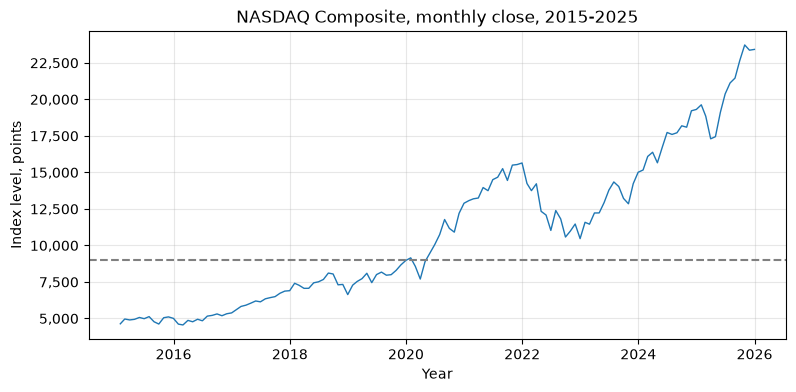

In [56]:
import matplotlib.ticker as mtick

nasdaq = pd.read_csv("../data/NASDAQ.csv")
nasdaq["Date"] = pd.to_datetime(nasdaq["Date"], format="%Y-%m-%d")
prices = nasdaq.set_index("Date").sort_index()["NASDAQ"]

monthly = prices.resample("ME").last()
recent = monthly[monthly.index >= "2015-01-01"]

level_2019 = prices.loc["2019"].iloc[-1]

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(recent.index, recent.values, linewidth=1)

ax.axhline(level_2019, color="gray", linestyle="--")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(True, alpha=0.3)
ax.set_xlabel("Year")
ax.set_ylabel("Index level, points")
ax.set_title("NASDAQ Composite, monthly close, 2015-2025")
plt.show()


### Saying something on the figure

`ax.text` puts a string on the figure at coordinates you give **in the units of the data** - so on this figure the x coordinate has to be a date, a `pd.Timestamp` again.

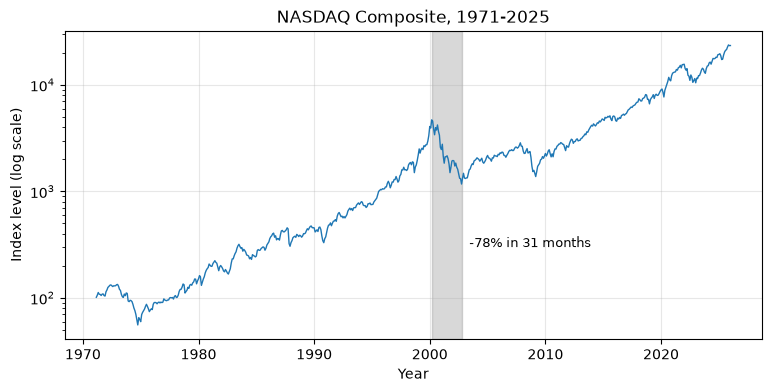

In [74]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(monthly.index, monthly.values, linewidth=1)

ax.axvspan(peak_date, low_date, color="gray", alpha=0.3)

ax.text(pd.Timestamp("2003-06-01"), 300, "-78% in 31 months", fontsize=9)

ax.set_yscale("log")
ax.grid(True, alpha=0.3)
ax.set_xlabel("Year")
ax.set_ylabel("Index level (log scale)")
ax.set_title("NASDAQ Composite, 1971-2025")

plt.show()

That figure now makes a claim, and a reader can check it against the line.

For the record, the index did not close above its March 2000 peak again until **April 2015** - fifteen years. Whether that belongs on the chart depends entirely on what you are arguing.

### Styles

`plt.style.use` changes the defaults for everything drawn afterwards - background, grid, colors, fonts - in one line. `plt.style.available` lists what your installation has.

In [75]:
print(plt.style.available)

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


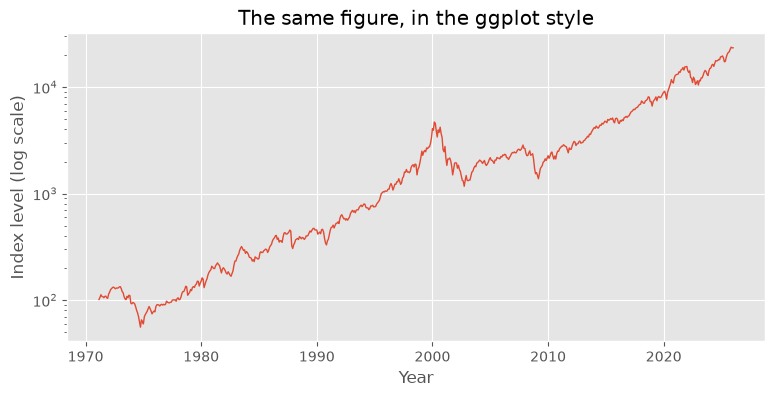

In [76]:
plt.style.use("ggplot")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(monthly.index, monthly.values, linewidth=1)

ax.set_yscale("log")
ax.set_xlabel("Year")
ax.set_ylabel("Index level (log scale)")
ax.set_title("The same figure, in the ggplot style")

plt.show()

> ⚠️ **Warning:** `plt.style.use` is **global and sticky**. Every figure you draw for the rest of the session uses it, including the ones above if you re-run them. `plt.style.use("default")` puts it back.

Style sheets are worth exactly one line at the top of a notebook and no more thought than that. A consistent look across a report matters; which look it is does not.

In [77]:
plt.style.use("default")

## Several panels in one figure

`plt.subplots` has been making one set of axes because we never asked it for more. `nrows` and `ncols` ask for a grid, and then instead of a single `ax` you get an **array** of them.

<class 'numpy.ndarray'>
shape: (2,)


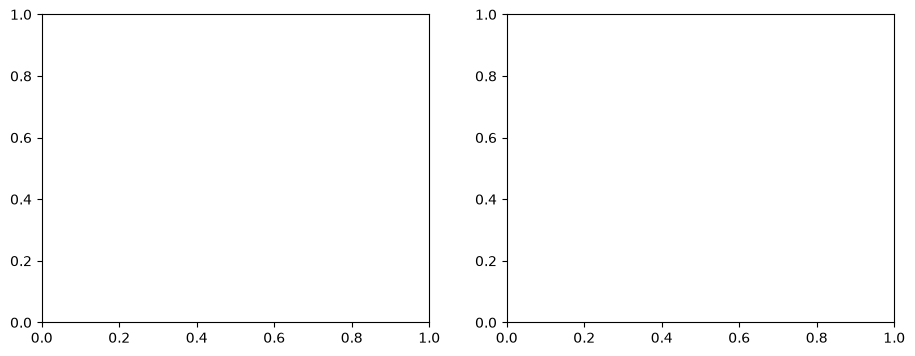

In [78]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4))

print(type(axes))
print("shape:", axes.shape)

A NumPy array of two `Axes` objects, so `axes[0]` is the left panel and `axes[1]` the right one. Each of them takes exactly the same methods as before, and the figure as a whole gets its own overall title from `fig.suptitle`.

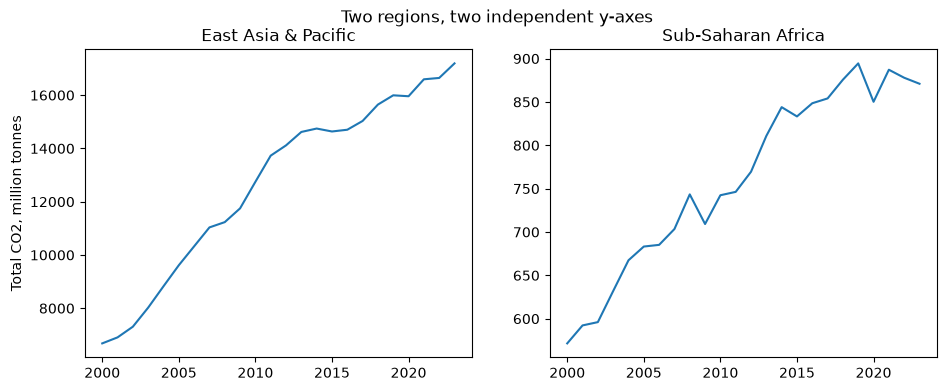

In [79]:
east = panel[panel["region"] == "East Asia & Pacific"].groupby("year")["co2_total"].sum()
africa = panel[panel["region"] == "Sub-Saharan Africa"].groupby("year")["co2_total"].sum()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4))

axes[0].plot(east.index, east.values)
axes[0].set_title("East Asia & Pacific")
axes[0].set_ylabel("Total CO2, million tonnes")

axes[1].plot(africa.index, africa.values)
axes[1].set_title("Sub-Saharan Africa")

fig.suptitle("Two regions, two independent y-axes")

plt.show()

But the figure is **misleading**. Both lines rise at roughly the same angle to roughly the same height, so the two regions look comparable. They are not: East Asia ends 2023 at 17 193 million tonnes and Sub-Saharan Africa at 871, a factor of twenty. Each panel silently chose its own y-axis to fit its own data.

`sharey=True` makes every panel use one y-axis.

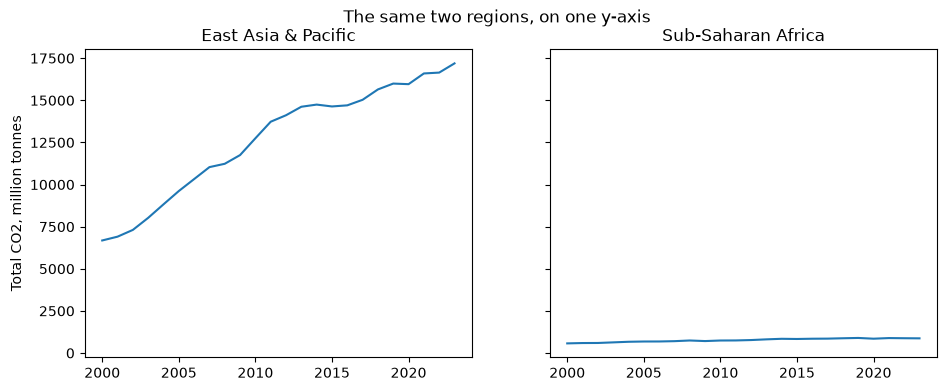

In [80]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4), sharey=True)

axes[0].plot(east.index, east.values)
axes[0].set_title("East Asia & Pacific")
axes[0].set_ylabel("Total CO2, million tonnes")

axes[1].plot(africa.index, africa.values)
axes[1].set_title("Sub-Saharan Africa")

fig.suptitle("The same two regions, on one y-axis")

plt.show()

Sub-Saharan Africa is now a nearly flat line along the bottom, which is what the data says. There is also `sharex=True`, which does the same for the x-axis and is worth having whenever the panels cover the same period.

> ⚠️ **Warning:** Panels side by side are an invitation to compare them. If their axes differ, the comparison the reader makes is not the one the numbers support. Either share the axis or say loudly on the figure that you did not.

### A grid of panels

Ask for two rows *and* two columns and the array of axes becomes two-dimensional - a grid, with one entry per panel. A panel is now picked out by two numbers, row first and column second:

shape: (2, 2)


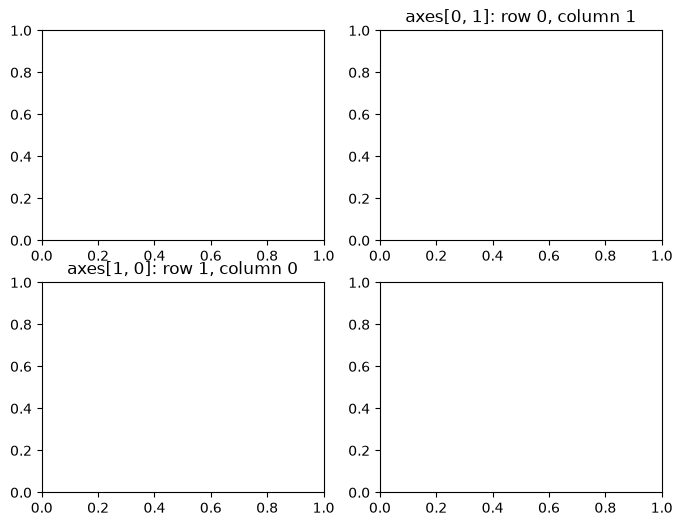

In [81]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 6))

print("shape:", axes.shape)

axes[0, 1].set_title("axes[0, 1]: row 0, column 1")
axes[1, 0].set_title("axes[1, 0]: row 1, column 0")

plt.show()

Notice that the lower titles run into the tick labels of the panels above them. `fig.tight_layout()` fixes that: it shuffles the panels so titles and labels stop colliding, and it goes last, once everything else is on the figure.

Two numbers per panel is fine when you fill four panels by hand. It is awkward in a loop, which wants one sequence to walk through. `axes.flatten()` turns the grid into a flat array, read row by row, and `enumerate` walks through it exactly as it would any other sequence:

shape: (4,)


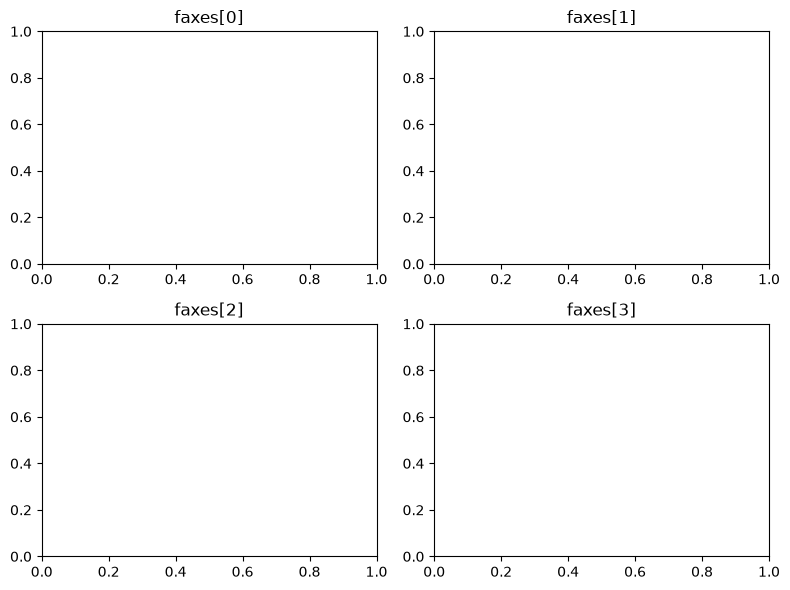

In [82]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 6))

faxes = axes.flatten()
print("shape:", faxes.shape)

for i, ax in enumerate(faxes):
    ax.set_title(f"faxes[{i}]")

fig.tight_layout()
plt.show()

### A panel per group, with a loop

Seven regions want a grid, and a grid of `nrows=2, ncols=4` has eight cells. The loop walks through the flattened axes and draws one region in each, and `ax.set_visible` hides the eighth panel, which has nothing in it.

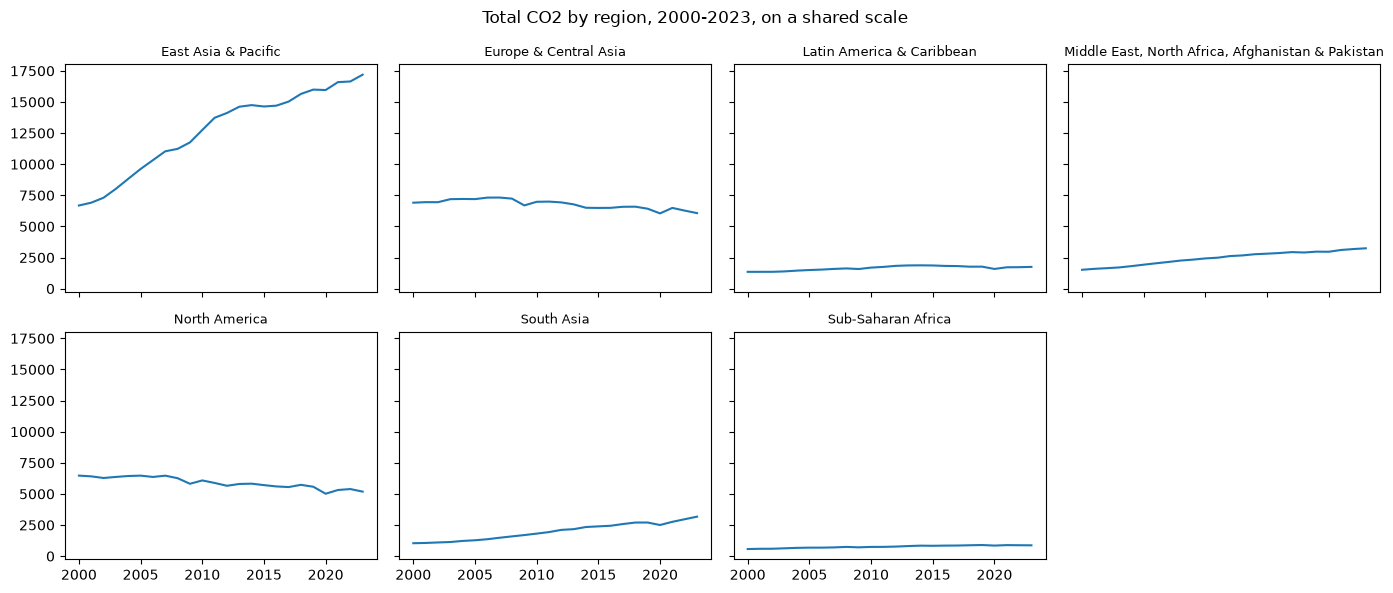

In [83]:
regions = sorted(panel["region"].unique())

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(14, 6), sharex=True, sharey=True)

faxes = axes.flatten()

for i, ax in enumerate(faxes):
    if i < len(regions):
        region = regions[i]
        rows = panel[panel["region"] == region].groupby("year")["co2_total"].sum()
        ax.plot(rows.index, rows.values)
        ax.set_title(region, fontsize=9)
    else:
        ax.set_visible(False)

fig.suptitle("Total CO2 by region, 2000-2023, on a shared scale")

fig.tight_layout()
plt.show()

Three things in that cell are worth naming:
- **The `if` guards the mismatch.** There are eight panels and seven regions, so `i < len(regions)` is what stops the loop from asking for a region that does not exist. A grid almost never fits the number of groups exactly, and this is the line that makes that harmless.
- **`ax.set_visible`** simply hides the axes object from view (does not delete it)
- **`fig.tight_layout()`** goes last again, after every panel has been drawn.

Seven panels for the price of four lines of drawing code, and adding an eighth region changes nothing except the number of rows in the grid.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Build a two-panel figure. In a single cell, draw two panels side by side for 2023: on the left a histogram of <code>co2_pc</code>, on the right a scatter of <code>gdp_pc</code> against <code>co2_pc</code>. Give each panel its own axis labels and title, and the figure a <code>suptitle</code>.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>df = load_panel()
df = df[df["year"] == 2023]</code></pre>

</div>

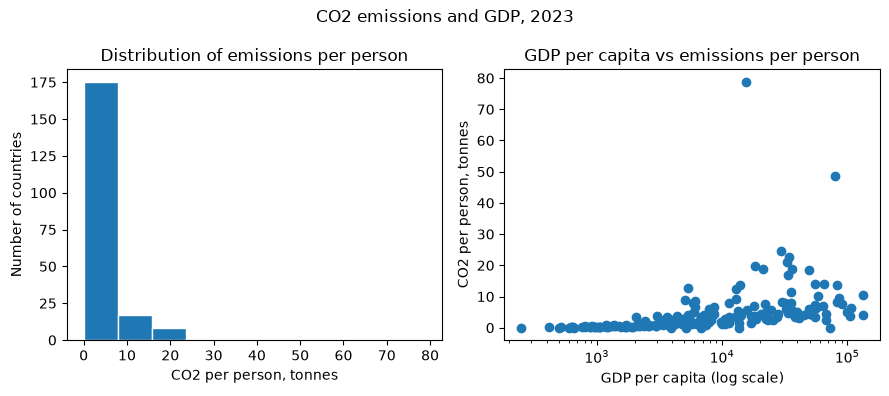

In [96]:
df = load_panel()
df = df[df["year"]==2023]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(9,4))

axes[0].hist(df["co2_pc"], edgecolor="white")
axes[1].set_xscale("log")
axes[1].scatter(df["gdp_pc"], df["co2_pc"])
axes[0].set_title("Distribution of emissions per person")
axes[0].set_xlabel("CO2 per person, tonnes")
axes[0].set_ylabel("Number of countries")

axes[1].set_title("GDP per capita vs emissions per person")
axes[1].set_xlabel("GDP per capita (log scale)")
axes[1].set_ylabel("CO2 per person, tonnes")


fig.suptitle("CO2 emissions and GDP, 2023")
fig.tight_layout()
plt.show()



### The same charts, straight from pandas

Apart from the one-liner we started with, everything in this notebook has gone through `fig, ax = plt.subplots()`. That is the version worth learning, because it is the one that never runs out. But pandas can draw all of the same charts directly off a Series or a DataFrame, and for a quick look it is hard to beat.

`kind=` chooses the chart: `"line"` (the default), `"bar"`, `"barh"`, `"hist"`, `"scatter"`, `"box"`. The labels and the title are keyword arguments.

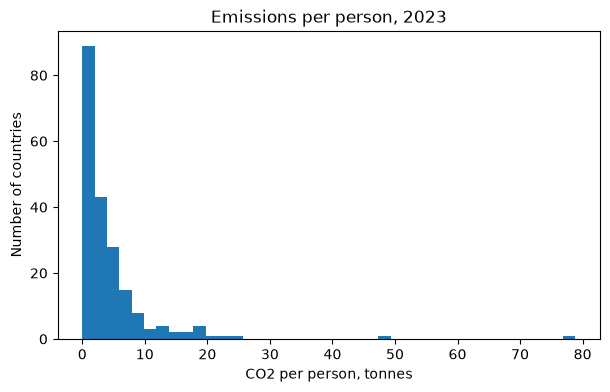

In [67]:
panel = load_panel()

year_2023 = panel[panel["year"] == 2023]

year_2023["co2_pc"].plot(
    kind="hist",
    bins=40,
    figsize=(7, 4),
    title="Emissions per person, 2023",
    xlabel="CO2 per person, tonnes",
    ylabel="Number of countries",
)

plt.show()

One call instead of six lines, and the same chart as the histogram earlier.

The trade is flexibility. There is no `ax` to hang a second series on, no reference line, no shading, no formatter - the moment you want any of that you are back to `plt.subplots`.

Which is where the two meet. **`df.plot()` is not a different system**: it builds a `fig` and an `ax` for you, and `ax=` lets you hand it one you made yourself. So you can let pandas draw and matplotlib finish.

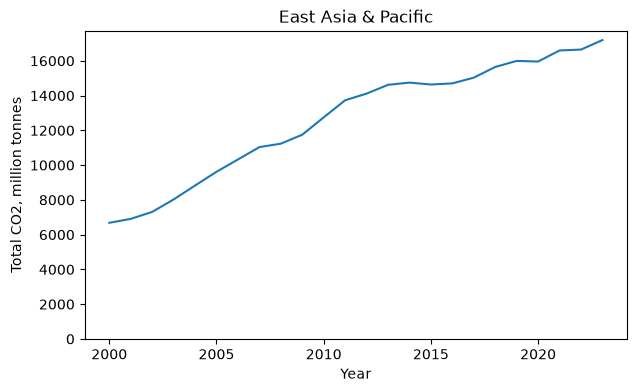

In [97]:
east_asia = panel[panel["region"] == "East Asia & Pacific"]
yearly = east_asia.groupby("year")["co2_total"].sum().reset_index()

fig, ax = plt.subplots(figsize=(7, 4))

yearly.plot(x="year", y="co2_total", ax=ax, legend=False)

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.set_title("East Asia & Pacific")
ax.set_ylim(0, None)

plt.show()

That is a reasonable habit: pandas for the drawing, matplotlib for the finishing.

This is also where the wide table pays off. Handed a whole DataFrame, `.plot()` draws **one line per column**, labels each line with its column name and uses the index as the x-axis - the loop over columns we wrote by hand earlier, in one call:

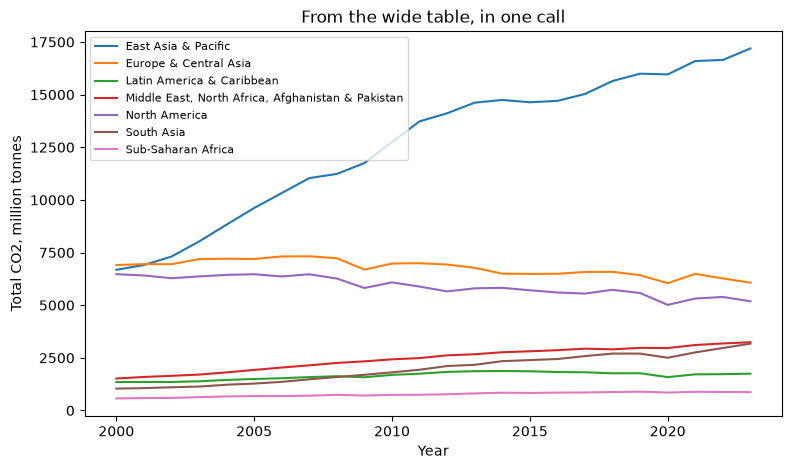

In [69]:
regional = panel.groupby(["region", "year"])["co2_total"].sum().reset_index()
wide = regional.pivot(index="year", columns="region", values="co2_total")

fig, ax = plt.subplots(figsize=(9, 5))

wide.plot(ax=ax)

ax.set_xlabel("Year")
ax.set_ylabel("Total CO2, million tonnes")
ax.legend(fontsize=8)
ax.set_title("From the wide table, in one call")

plt.show()

And pandas will build a grid for you too. `subplots=True` gives each column its own panel, with the column name in its legend, and `layout=` says how to arrange them - the one-line version of the panel grid above.

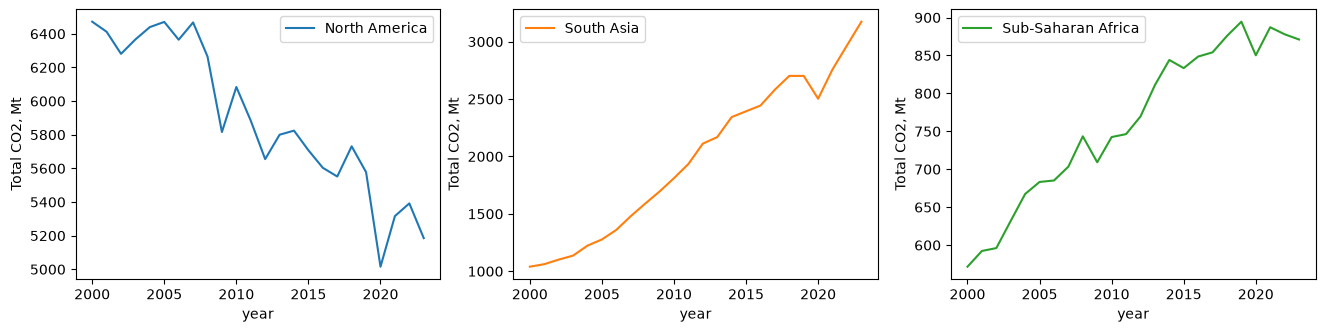

In [98]:
wide[["North America", "South Asia", "Sub-Saharan Africa"]].plot(
    subplots=True,
    layout=(1, 3),
    figsize=(16, 3.5),
    ylabel="Total CO2, Mt",
)

plt.show()

> 💡 **Tip:** Reach for `df.plot()` while you are still looking at the data, and for `plt.subplots()` once you know what the figure is going to say.

## A function that draws a figure

Look back at the panel loop. Every panel needed the same handful of lines with one thing changed. Look back at the bar chart of 2023: it would need the same treatment for 2010, and for 2000, and for every year somebody asks about.

That is the situation functions exist for, and nothing about the fact that the output is a picture rather than a number changes the rules from Part 1.

In [71]:
def plot_region(data, region):
    """
    Draw total CO2 emissions over time for one region.

    Parameters
    ----------
    data : DataFrame
        Panel with columns "region", "year" and "co2_total".
    region : str
        Name of the region to draw. Must appear in data["region"].
    
    Returns
    -------
    Figure
        The finished figure.

    Raises
    ------
    ValueError
        If region is not one of the regions in data.
    """

    if region not in data["region"].unique():
        raise ValueError(f"no region called '{region}' in this table")

    rows = data[data["region"] == region].groupby("year")["co2_total"].sum()

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.plot(rows.index, rows.values)

    ax.set_xlabel("Year")
    ax.set_ylabel("Total CO2, million tonnes")
    ax.set_title(f"{region}: total CO2 emissions")
    ax.grid(True, alpha=0.3)

    return fig

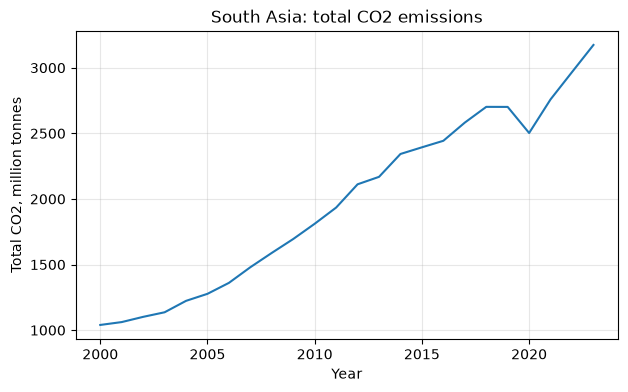

In [72]:
fig = plot_region(panel, "South Asia")

Four decisions in there are worth stating, because they are the difference between a function you can use and one you rewrite every time.

**The data is a parameter.** `plot_region` never mentions `panel`. A function that reaches out for a variable defined somewhere else in the notebook works exactly once - in that notebook, in that order, after that cell has been run. Passing the table in costs one word and makes the function portable.

**It returns `fig`.** In a notebook the figure appears whether you return it or not, so this looks pointless - and it is what lets the caller save it, put it in a report, or change something afterwards. A function that draws and returns nothing is a dead end.

**The parameter goes in the title.** `f"{region}: total CO₂ emissions"` - so that seven figures produced by seven calls are not seven identical-looking pictures you cannot tell apart. If a function takes an argument, that argument belongs in the title.

**It refuses bad input.** `raise ValueError` with a message naming what was wrong, rather than returning an empty chart. An empty chart is the worst possible outcome: it does not look like an error, so it gets used.

In [73]:
# ValueError - a spelling nobody would notice in an empty figure
plot_region(panel, "South-Asia")

ValueError: no region called 'South-Asia' in this table

And now the thing the function was for:

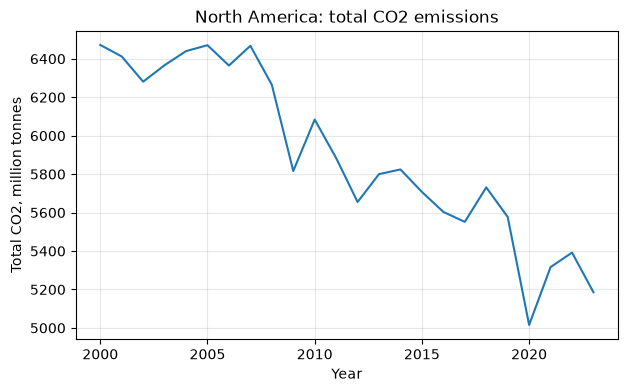

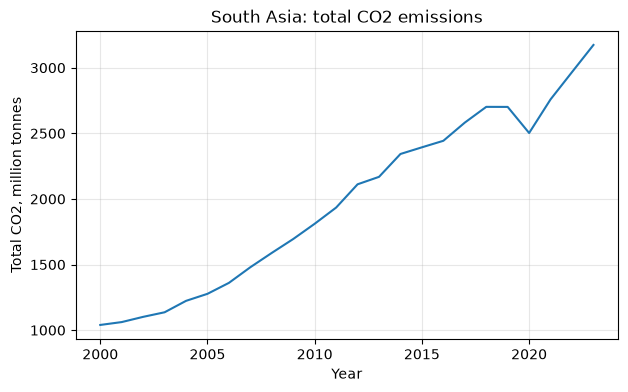

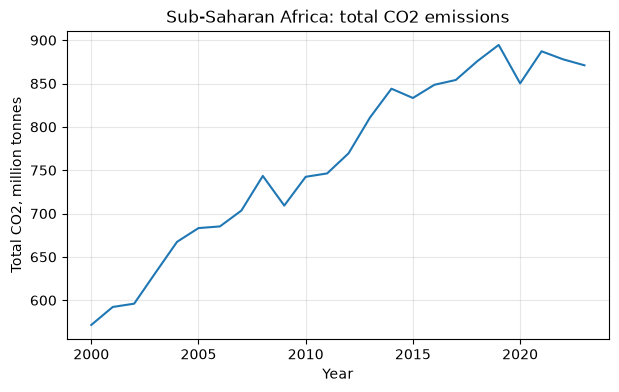

In [99]:
for region in ["North America", "South Asia", "Sub-Saharan Africa"]:
    plot_region(panel, region)

Three figures, two lines.

> 💡 **Tip:** The moment you copy a plotting cell and change one string in it, write the function. The second copy is where it pays for itself, and the fourth is where doing it by hand starts producing figures that disagree with each other about the axis limits.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">
<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Write a plotting function. In a single cell, load the file below and write <code>plot_year(data, year)</code>, which draws a scatter of <code>weight</code> against <code>mpg</code> for the cars of one model year, labels both axes, and puts the year in the title. Give it a docstring, and demonstrate it for the 1976 cars - note that <code>model_year</code> stores 1976 as <code>76</code>.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>cars = pd.read_excel("../data/mpg.xlsx")</code></pre>

</div>

In [ ]:
cars = pd.read_excel("../data/mpg.xlsx")

def plot_year(data, year):
    """
    Draw a scatter of weight against mpg for the cars of one model year.

    Parameters
    ----------
    data : DataFrame
        Car data with the columns model_year, weight and mpg.
        model_year stores the year as two digits (76 for 1976).
    year : int
        Model year as a four-digit number, for example 1976.
    """
    rows = data[data["model_year"] == year - 1900]

    fig, ax = plt.subplots()
    ax.scatter(rows["weight"], rows["mpg"])
    ax.set_xlabel("Weight, lbs")
    ax.set_ylabel("Fuel economy, miles per gallon")
    ax.set_title(f"Weight vs fuel economy, model year {year}")
    plt.show()

plot_year(cars, 1976)


,mpg,cylinders,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...
393,27.0,4,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,79.0,2625,18.6,82,usa,ford ranger


## Saving a figure

A figure that only exists inside a notebook cannot go in a report. `fig.savefig` writes it to a file, and it belongs to `fig` rather than `ax` because it is the whole picture that gets written.

In [ ]:
fig = plot_region(panel, "Europe & Central Asia")

fig.savefig("regional-emissions.png", dpi=150, bbox_inches="tight")
print("written")

Three things to know about it.

**The format comes from the file extension.** `.png` gives you a grid of pixels, which is what you want for a slide or a web page. `.pdf` and `.svg` give you a description of the shapes, which stays sharp at any size - use those for anything going into a printed document.

**`dpi` is dots per inch**, and it decides how big the pixel grid is. Combined with `figsize`, which is in inches, it fixes the size of the file: 7 by 4 inches at 150 dpi is 1050 by 600 pixels. 150 is fine for a screen; use at least 300 for print.

**`bbox_inches="tight"`** crops the whitespace around the figure and, more usefully, rescues labels that were running off the edge.


> ⚠️ **Warning:** In a script, `plt.show()` displays the figure and then throws it away, so `fig.savefig` afterwards writes a blank file. **Save first, show second** - or hold on to `fig`, as `plot_region` does, and the order stops mattering.

### Where the file goes, and what kind of file it is

`fig.savefig("regional-emissions.png", ...)` used a relative path, so the file landed in the notebook's own folder - the same rule as `../data/`. That is where
everything this course writes belongs: next to the notebook that made it, never in `data`.

The more important point is what kind of file it is. A saved figure is **derived**: the notebook made it, and running the notebook again makes it again. Delete it and nothing is lost.

That is worth holding on to: **the notebook is the record, and the figure is something it produces
on demand.** If the figure needs to change, you change the code and run it again - never the
picture.

## And what a figure is for

We have spent a session on how to draw things. The last few minutes are about whether to.

Every figure is an argument. The table of 203 countries in 2023 is a fact; the bar chart of seven regional means is a claim about it, and so is the histogram, and they say different things. Choosing the chart, sorting the categories, cutting the range into bins, fixing the axis limits, dropping the missing rows - none of those is a neutral act, and all of them were made by you.

So before a figure leaves your screen, three questions.

**What question does it answer?** If you cannot say it in one sentence, the figure is not finished. A chart made because you had the data rather than because you had a question is decoration, and readers can tell.

**Could a reader check it?** Axis labels with units, a title that names the subset, and somewhere a statement of how many rows are in it. If the figure summarizes, say which summary - *mean across countries* is a different chart from *mean across people*, and both are called "average".

**What would it look like if the claim were false?** This is the one that matters most, and this session gave you three cases where the answer is *exactly the same*. Timor-Leste's smooth twelve-year climb was a straight line drawn between two points. Norway's emissions, drawn from a table sorted by size, zigzagged like a market in a panic. Two panels side by side made a twentyfold difference look like no difference at all. None of the three produced an error, and none of them looked wrong.

That is the whole reason this session came after the wrangling rather than before it. A figure is the most persuasive thing you can make out of a table, and persuasiveness is not accuracy. Everything you learned about counting rows, checking merges and looking at missing values is what stands between a *convincing* figure and a *true* one.

## Additional resources

- [Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html) - matplotlib's own introduction, and the *Anatomy of a figure* diagram near the top is worth printing out
- [Axes API](https://matplotlib.org/stable/api/axes_api.html) - the full list of everything `ax` can do, which is where you go when you know what you want and not what it is called
- [Tick formatters](https://matplotlib.org/stable/api/ticker_api.html) - every ready-made formatter and locator, including the date ones
- [Chart visualization](https://pandas.pydata.org/docs/user_guide/visualization.html) - the pandas side, including every `kind=` that `df.plot()` accepts
- [Reshaping and pivot tables](https://pandas.pydata.org/docs/user_guide/reshaping.html) - `pivot`, `melt` and their more powerful relatives
- [SKL401](https://isabelhovdahl.github.io/skl401/) - topic 4 covers the same ground: 4.2 reshaping, 4.3 to 4.6 the four chart types, 4.7 customizing, 4.8 subplots and **4.9 plotting from pandas**, which has more demonstrations of `df.plot()`

**Next week:** putting a line through the scatter plot - linear regression, reading a model's output, and getting a table of results out of Python and into a document.